In [1]:
# ── Cell 1: Imports ────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)

# Gradient Boosting
import lightgbm as lgb
import xgboost as xgb

print('All imports OK')

All imports OK


In [2]:
# ── Cell 2: Download Dataset via Kaggle API ───────────────────────────────
import os, zipfile, io, requests

KAGGLE_KEY = 'KGAT_0b3e2563e3da66674caa61487dfb332b'
HEADERS    = {'Authorization': f'Bearer {KAGGLE_KEY}'}
BASE       = 'https://www.kaggle.com/api/v1/competitions/data/download/GiveMeSomeCredit'

def download_csv(filename, dest='/content'):
    url = f'{BASE}/{filename}'
    print(f'Downloading {filename} ...')
    r = requests.get(url, headers=HEADERS)
    r.raise_for_status()

    content = r.content
    magic = content[:4]
    print(f'  Response: {len(content)} bytes | Magic: {magic}')

    # Kaggle returns ZIP archives (PK\x03\x04)
    if magic[:2] == b'PK':
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            inner_name = z.namelist()[0]
            print(f'  Extracting: {inner_name}')
            content = z.read(inner_name)

    path = os.path.join(dest, filename)
    with open(path, 'wb') as f:
        f.write(content)
    print(f'  ✓ Saved: {path} ({len(content)/1e6:.1f} MB)')
    return path

TRAIN_FILE = download_csv('cs-training.csv')
TEST_FILE  = download_csv('cs-test.csv')

# ── Load data ──────────────────────────────────────────────────────────────
TARGET = 'SeriousDlqin2yrs'

raw_train = pd.read_csv(TRAIN_FILE)
if raw_train.columns[0].startswith('Unnamed') or raw_train.columns[0] == '':
    raw_train = raw_train.iloc[:, 1:]
print(f'\n✓ Training data : {raw_train.shape}')

raw_external_test = pd.read_csv(TEST_FILE)
if raw_external_test.columns[0].startswith('Unnamed') or raw_external_test.columns[0] == '':
    raw_external_test = raw_external_test.iloc[:, 1:]
print(f'✓ External test : {raw_external_test.shape}')

print(f'\nColumns: {raw_train.columns.tolist()}')
raw_train.head()

  Response: 2791537 bytes | Magic: b'PK\x03\x04'
  Extracting: cs-training.csv
  ✓ Saved: /content/cs-training.csv (7.6 MB)
  Response: 1880688 bytes | Magic: b'PK\x03\x04'
  Extracting: cs-test.csv
  ✓ Saved: /content/cs-test.csv (5.0 MB)

✓ Training data : (150000, 11)
✓ External test : (101503, 11)

Columns: ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
# ── Cell 3: Data Preprocessing ─────────────────────────────────────────────

# Target variable
TARGET = 'SeriousDlqin2yrs'

# Feature columns (excluding target)
FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]


def preprocess_gmsc(input_df, is_train=True):
    data = input_df.copy()

    # Keep only required columns + target (if present)
    keep_cols = FEATURES + ([TARGET] if (is_train and TARGET in data.columns) else [])
    data = data[keep_cols]

    # Fill missing values
    data['MonthlyIncome'] = data['MonthlyIncome'].fillna(data['MonthlyIncome'].median())
    data['NumberOfDependents'] = data['NumberOfDependents'].fillna(0)

    # Remove clear outliers
    data = data[(data['age'] > 18) & (data['age'] < 100)]
    data = data[data['RevolvingUtilizationOfUnsecuredLines'] < 10]

    # Remove records with sentinel delinquency values
    for col in [
        'NumberOfTime30-59DaysPastDueNotWorse',
        'NumberOfTimes90DaysLate',
        'NumberOfTime60-89DaysPastDueNotWorse'
    ]:
        data = data[data[col] < 20]

    return data.reset_index(drop=True)


# Preprocess labeled training data
df = preprocess_gmsc(raw_train, is_train=True)

print(f'Clean training dataset shape: {df.shape}')
print(f'\nClass distribution:')
print(df[TARGET].value_counts())
print(f'\nClass imbalance ratio: {df[TARGET].value_counts()[0] / df[TARGET].value_counts()[1]:.2f}:1')

# Preprocess optional external test file for later scoring
df_external_test = None
if 'raw_external_test' in globals() and raw_external_test is not None:
    # External test is usually unlabeled in Kaggle competition
    has_label = TARGET in raw_external_test.columns and raw_external_test[TARGET].notna().sum() > 0
    df_external_test = preprocess_gmsc(raw_external_test, is_train=has_label)
    print(f'\nExternal test prepared: {df_external_test.shape} | labeled={has_label}')

Clean training dataset shape: (149476, 11)

Class distribution:
SeriousDlqin2yrs
0    139615
1      9861
Name: count, dtype: int64

Class imbalance ratio: 14.16:1

External test prepared: (101132, 10) | labeled=False


In [7]:
# ── Cell 4: Train/Test Split ───────────────────────────────────────────────

X = df[FEATURES].values
y = df[TARGET].values

# Stratified split to maintain class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set    : {X_test.shape[0]} samples')
print(f'\nTrain class distribution: {np.bincount(y_train)}')
print(f'Test class distribution : {np.bincount(y_test)}')

Training set: 119580 samples
Test set    : 29896 samples

Train class distribution: [111691   7889]
Test class distribution : [27924  1972]


In [8]:
# -- Cell 5: Model Definitions + Graph Feature Builder -------------------------

from sklearn.neighbors import NearestNeighbors
from scipy import sparse


def build_graph_augmented_features(X_train_raw, X_eval_raw, *, n_neighbors=20, alpha=0.70, n_steps=2):
    """
    Build graph-augmented features using similarity edges + message passing.
    This captures local/global context between similar applications.
    """
    X_all = np.vstack([X_train_raw, X_eval_raw]).astype(np.float32)

    # Scale before graph construction so distance is feature-balanced
    graph_scaler = StandardScaler()
    X_all_scaled = graph_scaler.fit_transform(X_all)

    n_total = X_all_scaled.shape[0]
    k = min(n_neighbors + 1, n_total)

    nn = NearestNeighbors(n_neighbors=k, metric='cosine')
    nn.fit(X_all_scaled)
    distances, indices = nn.kneighbors(X_all_scaled)

    # Remove self-neighbor (first column)
    distances = distances[:, 1:]
    indices = indices[:, 1:]

    similarities = np.clip(1.0 - distances, 0.0, 1.0)

    rows = np.repeat(np.arange(n_total), similarities.shape[1])
    cols = indices.reshape(-1)
    vals = similarities.reshape(-1)

    A = sparse.csr_matrix((vals, (rows, cols)), shape=(n_total, n_total))
    A = A.maximum(A.T)
    A = A + sparse.eye(n_total, format='csr')

    degree = np.asarray(A.sum(axis=1)).ravel()
    degree_inv = sparse.diags(1.0 / np.maximum(degree, 1e-12))
    A_norm = degree_inv @ A

    # GCN-style iterative propagation
    H0 = X_all_scaled
    H = H0
    for _ in range(n_steps):
        H = alpha * (A_norm @ H) + (1.0 - alpha) * H0

    X_graph = np.hstack([X_all_scaled, np.asarray(H)])

    n_train = X_train_raw.shape[0]
    return X_graph[:n_train], X_graph[n_train:]


GRAPH_CFG = {
    'n_neighbors': 20,
    'alpha': 0.70,
    'n_steps': 2
}

# Graph features are materialized in Cell 6 after split variables exist.
X_train_graph, X_test_graph = None, None

# Dictionary to store models and results
models = {}
results = {}

# ============================================================================
# BASELINE 1: Logistic Regression
# ============================================================================
models['Logistic Regression'] = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# ============================================================================
# BASELINE 2: Random Forest
# ============================================================================
models['Random Forest'] = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# ============================================================================
# MAIN MODEL: LightGBM
# ============================================================================
models['LightGBM'] = lgb.LGBMClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# ============================================================================
# ALTERNATIVE: XGBoost
# ============================================================================
if 'y_train' in globals():
    scale_pos_weight = np.sum(y_train == 0) / np.sum(y_train == 1)
else:
    scale_pos_weight = 1.0
    print('y_train not found yet. Run Cell 4 before Cell 6 to set proper class weight.')

models['XGBoost'] = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    eval_metric='auc',
    use_label_encoder=False
)

# ============================================================================
# GRAPH-BASED MODEL: Graph-Augmented LightGBM
# ============================================================================
models['Graph-Augmented LightGBM'] = lgb.LGBMClassifier(
    n_estimators=400,
    max_depth=10,
    learning_rate=0.05,
    num_leaves=63,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print('Models defined:')
for name in models:
    print(f'  • {name}')

Models defined:
  • Logistic Regression
  • Random Forest
  • LightGBM
  • XGBoost
  • Graph-Augmented LightGBM


In [9]:
# -- Cell 6: Train & Evaluate All Models --------------------------------------

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


required_vars = ['X_train', 'X_test', 'y_train', 'y_test', 'X_train_scaled', 'X_test_scaled']
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(
        f"Missing split variables: {missing_vars}. Run Cell 4 before Cell 6."
    )

if 'models' not in globals() or len(models) == 0:
    raise RuntimeError('Models are not defined. Run Cell 5 before Cell 6.')

# Build graph view only when needed and only after split variables exist.
if (
    'X_train_graph' not in globals() or
    'X_test_graph' not in globals() or
    X_train_graph is None or
    X_test_graph is None
):
    X_train_graph, X_test_graph = build_graph_augmented_features(X_train, X_test, **GRAPH_CFG)

# Ensure XGBoost imbalance handling is computed from the current training split.
if 'XGBoost' in models:
    xgb_weight = np.sum(y_train == 0) / np.sum(y_train == 1)
    models['XGBoost'].set_params(scale_pos_weight=xgb_weight)


def graph_model_cv_scores(X_raw, y_raw, graph_cfg, model_params, cv_splitter):
    """Manual CV so graph features are rebuilt fold-by-fold (no leakage)."""
    scores = []

    for tr_idx, val_idx in cv_splitter.split(X_raw, y_raw):
        X_fold_tr_raw, X_fold_val_raw = X_raw[tr_idx], X_raw[val_idx]
        y_fold_tr, y_fold_val = y_raw[tr_idx], y_raw[val_idx]

        X_fold_tr, X_fold_val = build_graph_augmented_features(
            X_fold_tr_raw,
            X_fold_val_raw,
            **graph_cfg
        )

        fold_model = lgb.LGBMClassifier(**model_params)
        fold_model.fit(X_fold_tr, y_fold_tr)

        y_fold_prob = fold_model.predict_proba(X_fold_val)[:, 1]
        scores.append(roc_auc_score(y_fold_val, y_fold_prob))

    return np.array(scores)


for name, model in models.items():
    print(f'\n{"="*60}')
    print(f'Training: {name}')
    print(f'{"="*60}')

    # Select feature view for each model
    if name == 'Logistic Regression':
        X_tr, X_te = X_train_scaled, X_test_scaled
        feature_mode = 'scaled'
    elif name == 'Graph-Augmented LightGBM':
        X_tr, X_te = X_train_graph, X_test_graph
        feature_mode = 'graph'
    else:
        X_tr, X_te = X_train, X_test
        feature_mode = 'raw'

    # Train
    model.fit(X_tr, y_train)

    # Predictions
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    # Metrics
    roc_auc = roc_auc_score(y_test, y_prob)
    avg_precision = average_precision_score(y_test, y_prob)

    # Cross-validation
    if name == 'Logistic Regression':
        cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='roc_auc')
    elif name == 'Graph-Augmented LightGBM':
        cv_scores = graph_model_cv_scores(
            X_train,
            y_train,
            GRAPH_CFG,
            model.get_params(),
            cv
        )
    else:
        cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')

    # Store results
    results[name] = {
        'model': model,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'roc_auc': roc_auc,
        'avg_precision': avg_precision,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'feature_mode': feature_mode
    }

    if name == 'Graph-Augmented LightGBM':
        results[name]['graph_cfg'] = GRAPH_CFG.copy()

    print('\nClassification Report:')
    print(classification_report(y_test, y_pred, target_names=['No Default', 'Default']))
    print(f'ROC-AUC Score    : {roc_auc:.4f}')
    print(f'Avg Precision    : {avg_precision:.4f}')
    print(f'CV ROC-AUC       : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')


Training: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

  No Default       0.98      0.80      0.88     27924
     Default       0.21      0.75      0.33      1972

    accuracy                           0.80     29896
   macro avg       0.60      0.78      0.61     29896
weighted avg       0.93      0.80      0.85     29896

ROC-AUC Score    : 0.8591
Avg Precision    : 0.3881
CV ROC-AUC       : 0.8537 ± 0.0040

Training: Random Forest

Classification Report:
              precision    recall  f1-score   support

  No Default       0.98      0.82      0.89     27924
     Default       0.22      0.74      0.34      1972

    accuracy                           0.81     29896
   macro avg       0.60      0.78      0.61     29896
weighted avg       0.93      0.81      0.85     29896

ROC-AUC Score    : 0.8606
Avg Precision    : 0.3721
CV ROC-AUC       : 0.8564 ± 0.0036

Training: LightGBM

Classification Report:
              precision 

In [10]:
# ── Cell 7: Results Comparison Table ───────────────────────────────────────

comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'ROC-AUC': [r['roc_auc'] for r in results.values()],
    'Avg Precision': [r['avg_precision'] for r in results.values()],
    'CV ROC-AUC (mean)': [r['cv_mean'] for r in results.values()],
    'CV ROC-AUC (std)': [r['cv_std'] for r in results.values()]
}).sort_values('ROC-AUC', ascending=False)

print('\n' + '='*70)
print('MODEL COMPARISON SUMMARY')
print('='*70)
print(comparison_df.to_string(index=False))
print('\n')

# Identify best model
best_model_name = comparison_df.iloc[0]['Model']
best_auc = comparison_df.iloc[0]['ROC-AUC']
print(f'🏆 BEST MODEL: {best_model_name} (ROC-AUC = {best_auc:.4f})')


MODEL COMPARISON SUMMARY
                   Model  ROC-AUC  Avg Precision  CV ROC-AUC (mean)  CV ROC-AUC (std)
                LightGBM 0.864624       0.398593           0.859552          0.004428
           Random Forest 0.860591       0.372099           0.856379          0.003628
                 XGBoost 0.859821       0.387208           0.856838          0.003995
     Logistic Regression 0.859130       0.388123           0.853694          0.003964
Graph-Augmented LightGBM 0.857643       0.390599           0.851147          0.004842


🏆 BEST MODEL: LightGBM (ROC-AUC = 0.8646)


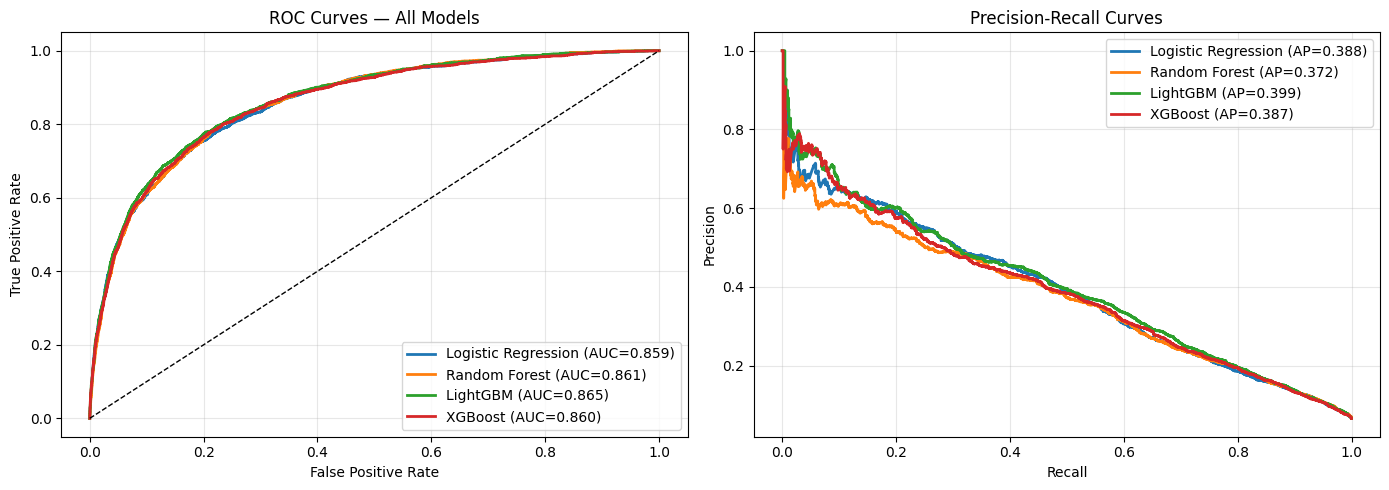

Figure saved: roc_pr_curves.png


In [24]:
# -- Cell 8: Visualisation - ROC Curves ---------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -- ROC Curves --
colors = sns.color_palette('tab10', len(results))
for (name, res), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC={res['roc_auc']:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves - All Models')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# -- Precision-Recall Curves --
for (name, res), color in zip(results.items(), colors):
    precision, recall, _ = precision_recall_curve(y_test, res['y_prob'])
    axes[1].plot(recall, precision, color=color, lw=2, label=f"{name} (AP={res['avg_precision']:.3f})")

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print('Figure saved: roc_pr_curves.png')

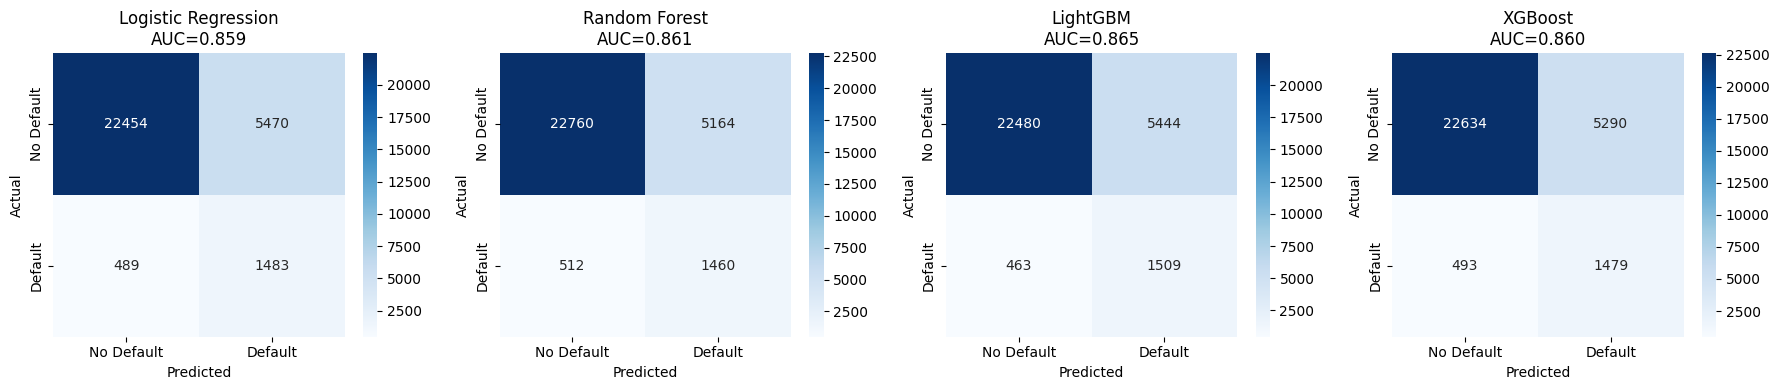

Figure saved: confusion_matrices.png


In [25]:
# -- Cell 9: Confusion Matrices ------------------------------------------------

num_models = len(results)
n_cols = min(3, num_models)
n_rows = int(np.ceil(num_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['No Default', 'Default'],
        yticklabels=['No Default', 'Default']
    )
    ax.set_title(f'{name}\nAUC={res["roc_auc"]:.3f}')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

# Hide any unused subplot slots
for ax in axes[num_models:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

print('Figure saved: confusion_matrices.png')

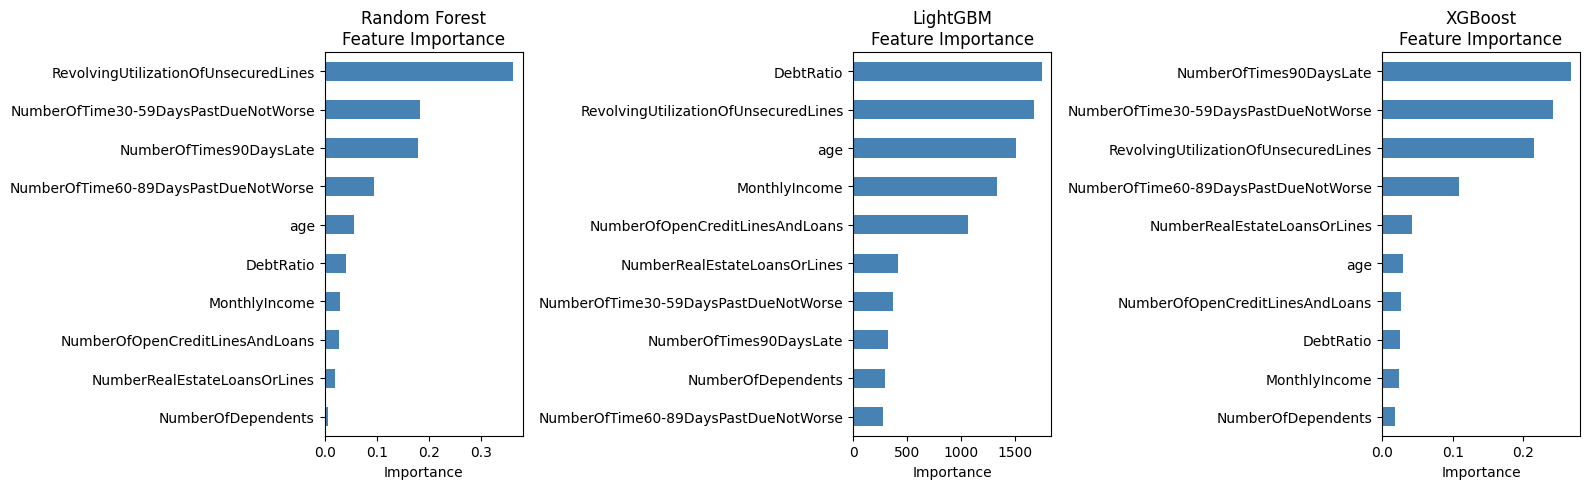

Figure saved: feature_importance.png


In [26]:
# ── Cell 10: Feature Importance (Tree Models) ───────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

tree_models = ['Random Forest', 'LightGBM', 'XGBoost']

for ax, name in zip(axes, tree_models):
    model = results[name]['model']
    importances = model.feature_importances_
    feat_imp = pd.Series(importances, index=FEATURES).sort_values()
    feat_imp.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'{name}\nFeature Importance')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Figure saved: feature_importance.png')

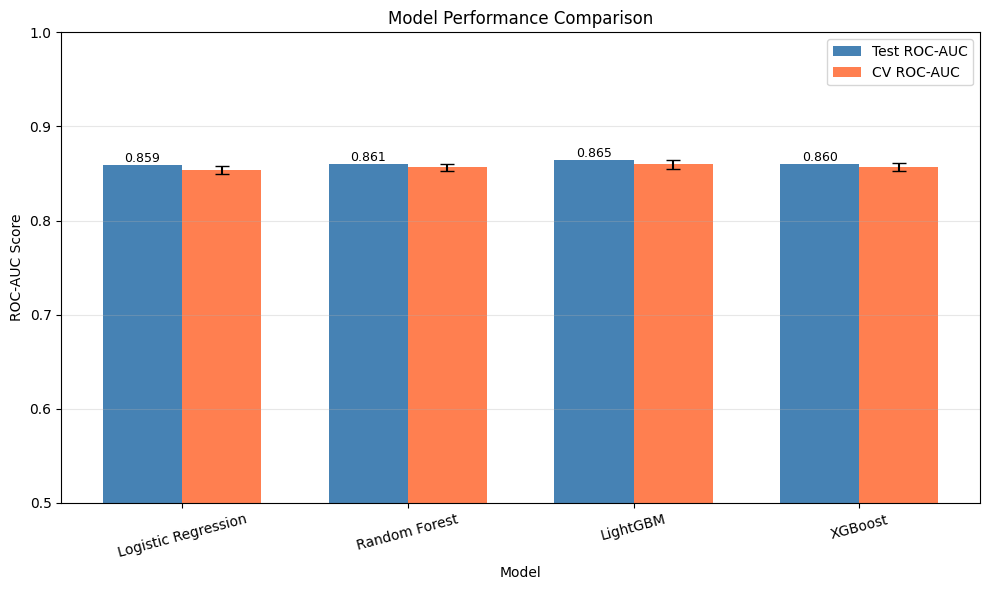

Figure saved: model_comparison.png


In [27]:
# ── Cell 11: Bar Chart Comparison ──────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 6))

model_names = list(results.keys())
auc_scores = [results[m]['roc_auc'] for m in model_names]
cv_scores = [results[m]['cv_mean'] for m in model_names]
cv_stds = [results[m]['cv_std'] for m in model_names]

x = np.arange(len(model_names))
width = 0.35

bars1 = ax.bar(x - width/2, auc_scores, width, label='Test ROC-AUC', color='steelblue')
bars2 = ax.bar(x + width/2, cv_scores, width, yerr=cv_stds, label='CV ROC-AUC', 
               color='coral', capsize=5)

ax.set_xlabel('Model')
ax.set_ylabel('ROC-AUC Score')
ax.set_title('Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15)
ax.legend()
ax.set_ylim(0.5, 1.0)
ax.grid(axis='y', alpha=0.3)

# Annotate bars
for bar, score in zip(bars1, auc_scores):
    ax.annotate(f'{score:.3f}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('Figure saved: model_comparison.png')

In [38]:
# -- Cell 12: Export Best Model -----------------------------------------------

try:
    from google.colab import files
    HAS_COLAB = True
except ImportError:
    HAS_COLAB = False

# Get best model
best_name = comparison_df.iloc[0]['Model']
best_result = results[best_name]
best_model = best_result['model']
best_auc = best_result['roc_auc']
feature_mode = best_result.get('feature_mode', 'raw')
graph_cfg = best_result.get('graph_cfg', None)

print(f'Exporting best model: {best_name}')
print(f'ROC-AUC: {best_auc:.4f}')
print(f'Feature mode: {feature_mode}')

# Bundle for CrediFlow backend
bundle = {
    'model': best_model,
    'scaler': scaler,
    'features': FEATURES,
    'model_name': best_name,
    'roc_auc': best_auc,
    'cv_auc': best_result['cv_mean'],
    'feature_mode': feature_mode,
    'graph_cfg': graph_cfg
}

MODEL_PATH = 'riskmodel.pkl'
joblib.dump(bundle, MODEL_PATH)

print(f'\nSaved model bundle: {MODEL_PATH}')
print('\nBundle contents:')
for key in bundle:
    if key not in ('model', 'scaler'):
        print(f'  - {key}: {bundle[key]}')

if HAS_COLAB:
    files.download(MODEL_PATH)
else:
    print('Not running in Colab: skipping automatic file download.')

# Optional: score external test file (if available)
if 'df_external_test' in globals() and df_external_test is not None:
    has_label = TARGET in df_external_test.columns and df_external_test[TARGET].notna().sum() > 0

    X_ext_raw = df_external_test[FEATURES].values

    if feature_mode == 'scaled':
        X_ext = scaler.transform(X_ext_raw)
    elif feature_mode == 'graph':
        # Rebuild graph features against the same train split used for model training
        _, X_ext = build_graph_augmented_features(X_train, X_ext_raw, **graph_cfg)
    else:
        X_ext = X_ext_raw

    ext_prob = best_model.predict_proba(X_ext)[:, 1]
    ext_pred = (ext_prob >= 0.5).astype(int)

    submission_df = pd.DataFrame({
        'Id': np.arange(1, len(df_external_test) + 1),
        'DefaultProbability': ext_prob,
        'PredictedLabel': ext_pred
    })

    if has_label:
        ext_auc = roc_auc_score(df_external_test[TARGET].values, ext_prob)
        print(f'\nExternal labeled test ROC-AUC: {ext_auc:.4f}')

    pred_path = 'external_test_predictions.csv'
    submission_df.to_csv(pred_path, index=False)
    print(f'Saved predictions: {pred_path}')

    if HAS_COLAB:
        files.download(pred_path)

print('\nExport complete')
print(f'Model path: {os.path.abspath(MODEL_PATH)}')
print(f'Size: {os.path.getsize(MODEL_PATH)/1e6:.2f} MB')

Exporting best model: LightGBM
ROC-AUC: 0.8646

✓ Model saved: riskmodel.pkl

Bundle contents:
  • features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
  • model_name: LightGBM
  • roc_auc: 0.8646235304577797
  • cv_auc: 0.859551951240471


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Predictions saved: external_test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Export complete

✓ File visible in Colab left sidebar: /content/riskmodel.pkl
  Size: 1.04 MB
